In [1]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

from interpmodules import helpers

Loaded aesthetics module


* __R1C1:__ \
Variogram models for empirical brain maps (Fig. S4A). It is counter-intuitive that more complex variogram models, stable and matern, provide consistently worse (worst) fit (larger MAE) relative to simpler models, in particular for those maps where the exponential variogram model was the best. This is because stable and matern models can fit the exponential curve under certain parameters. The authors may want to check their code at https://github.com/netneurolab/zhou_interpolates/blob/main/code/res2_neuromaps_full.ipynb, cell 141, particularly the shape parameter bound condition for model optimization. In addition, I recommend that upper bounds for other parameters should allow range > max(h), sill > max(ev), and a more flexible nugget, because extremely distant data in the map may remain related and measurement noise can be large. The fitting curves displayed in the notebook suggest that almost all variogram models are negatively impacted by the parameter bounds used.

In [2]:
import joblib
import pandas as pd

src_pvdata = joblib.load( projdir + '/data/fsLR-4k_reduced-midthickness_neuromaps.pkl')

maptags = pd.read_table(projdir + '/data/surf_map_names', delimiter = " ", dtype = str)
maptags = list(maptags.columns)

In [3]:
corder = ['gene expression', 'MEG', 'structural', 'functional', 'metabolism', 'expansion']
ccolours = [
    to_hex(plt.cm.terrain(0.2)),  # gene: light turquoise
    to_hex(plt.cm.spring(0.65)),  # MEG: orange
    to_hex(plt.cm.cubehelix(0.7)),  # structural: violet
    to_hex(plt.cm.terrain(0.3)),  # functional: green
    to_hex(plt.cm.nipy_spectral(0.3)), # metabolism: blue
    to_hex(plt.cm.spring(0.37)) # expansion: pink
]

cpal = dict(zip(corder, ccolours))
sns.color_palette(ccolours)

[(0.0, 0.6980392156862745, 0.6980392156862745),
 (1.0, 0.6509803921568628, 0.34901960784313724),
 (0.8117647058823529, 0.615686274509804, 0.8588235294117647),
 (0.19215686274509805, 0.8392156862745098, 0.4392156862745098),
 (0.0, 0.596078431372549, 0.8666666666666667),
 (1.0, 0.3686274509803922, 0.6313725490196078)]

In [15]:
import joblib
mapnames, h, all_ev = joblib.load( '/home/yzhou/gitrepo/interpolate/results/stats/neuromaps_collected_expvgm.pkl' )

In [4]:
Dist = helpers.internal_distance_matrix(src_pvdata.points, 'euclidean')

In [7]:
import gstools as gs
import skgstat as skg
skgstat_mdls = {'spherical': skg.models.spherical, 
                'exponential': skg.models.exponential,
                'gaussian': skg.models.gaussian,
                'cubic': skg.models.cubic,
                'stable': skg.models.stable,
                'matern': skg.models.matern,
               'hole': helpers.hole}

In [8]:
def semivariance(y1, y2):
    return .5 * (y1 - y2)**2

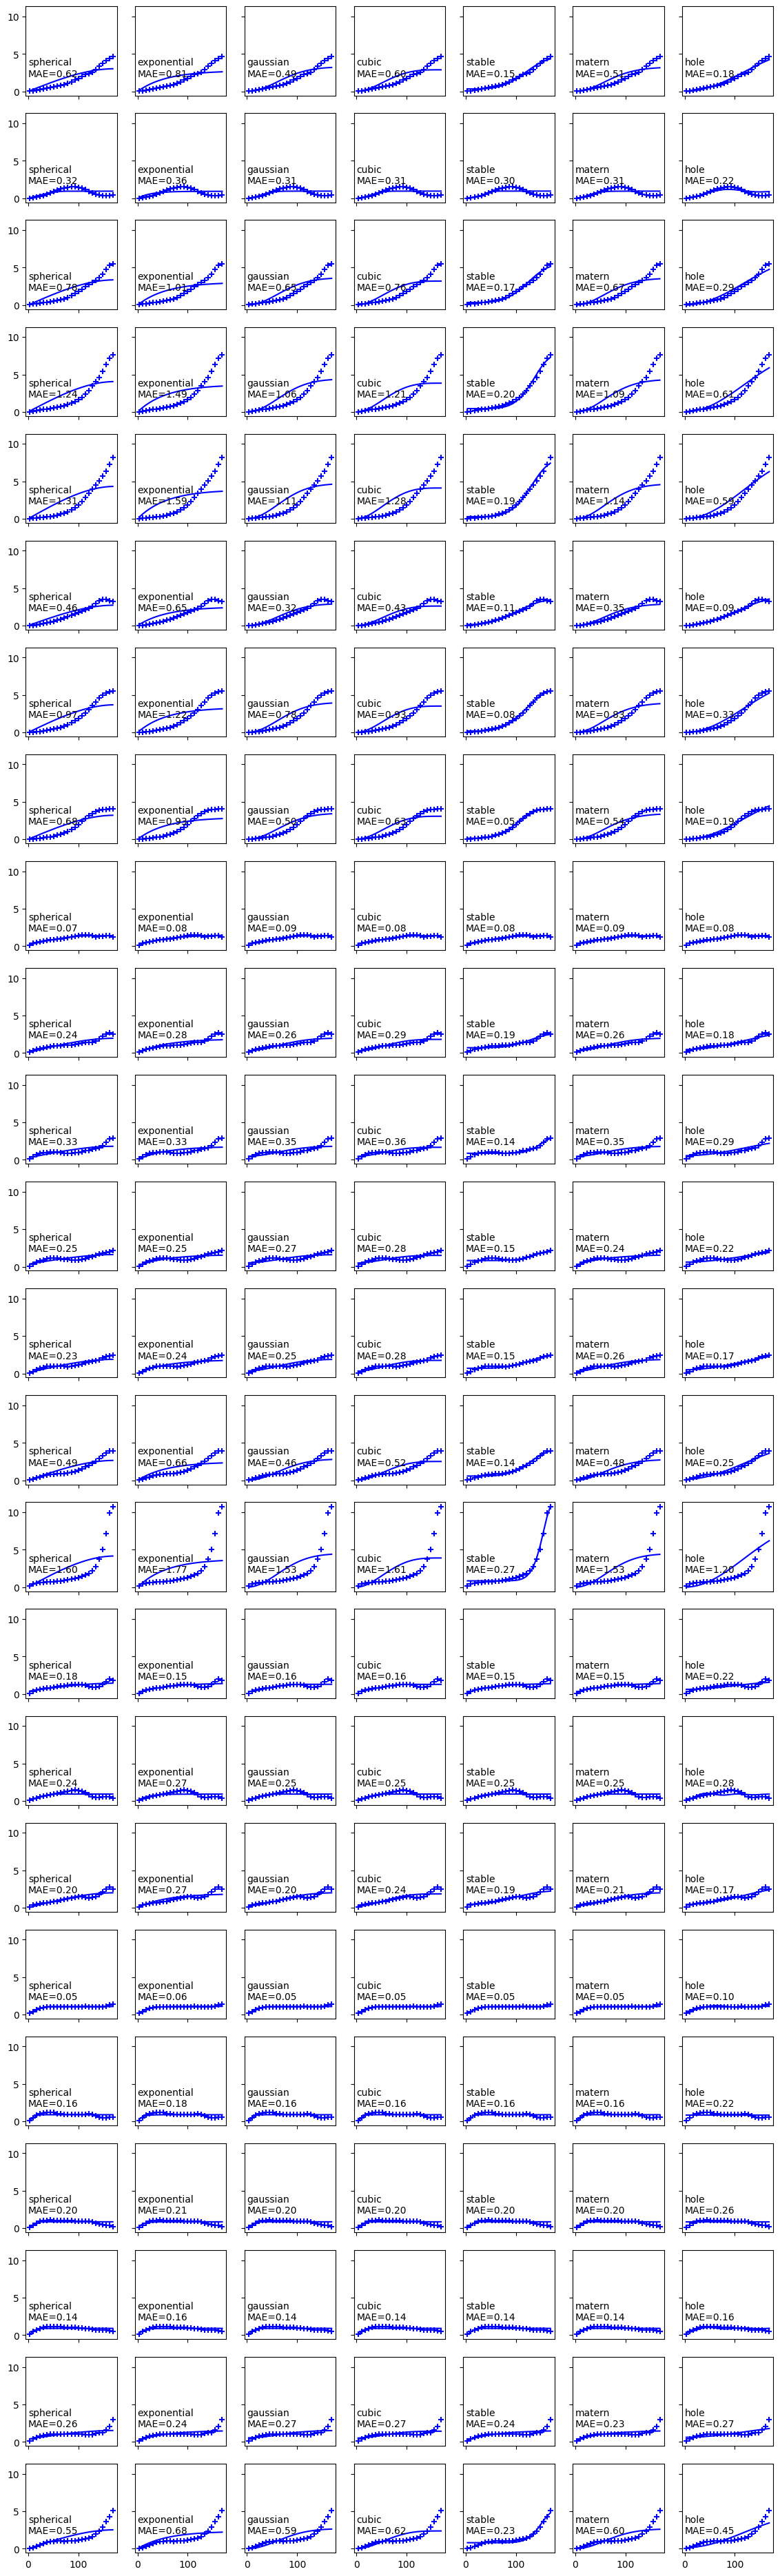

In [64]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics

fig, axs = plt.subplots(24,7, figsize = (14,48), sharex=True,sharey=True)

model_scores = {}

for mi, mapname in enumerate(mapnames):
    ev = all_ev[:,mi]
    nh = 25
    
    p0 = {3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
              4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
             }

    mapvals = zscore(src_pvdata[mapname])
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}
    
    cof = None; cov = None
    
    gof = {}
    
    for ind, model in enumerate(skgstat_mdls):
    
        axs[mi,ind].scatter(h, ev, marker = "+", color = 'b')
        
        
        if model in ['stable', 'matern']:
            cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[4], bounds = bounds[4], maxfev=1000)
        
        else:
            cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[3], bounds = bounds[3], maxfev=1000)

        
        v_pred = skgstat_mdls[model](h, *cof)
        x_s = np.linspace(h.min(), h.max())
        axs[mi, ind].plot(h, v_pred, color = 'b')
        mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
        r2 = r2_score(ev, v_pred, force_finite=False)
        gof[model] = r2
        
        axs[mi, ind].text(x=0, y=2,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))

    model_scores[mapname] = gof

In [65]:
import numpy as np

matrix = np.zeros((7, 24))

for mi, mapname in enumerate(maptags):
    matrix[:, mi] = pd.DataFrame( model_scores[mapname].values(), model_scores[mapname].keys() )[0].to_numpy()

In [66]:
extended_cpal = {}

from interpmodules import helpers

global_i_s = pd.DataFrame(index = maptags, columns = ['i'])

Dist = helpers.internal_distance_matrix(src_pvdata.points, 'geodesic')

for maptag in maptags:
    global_i = helpers.morans_i(Dist, src_pvdata[maptag], normalize=True)
    global_i_s.loc[maptag] = global_i

cat = []

maptocat = {'gene expression': ['abagen_genepc1'], \
            'MEG': ['hcps1200_meg' + fband for fband in fbands ] + ['hcps1200_megtimescale'], \
            'structural': ['hcps1200_thickness', 'hcps1200_myelinmap'], \
            'functional': ['margulies2016_fcgradient01', 'mueller2013_intersubjvar', 'xu2020_FChomology', 'sydnor2021_SAaxis'], \
            'metabolism': ['raichle_cbf', 'raichle_cbv', 'raichle_cmr02', 'raichle_cmrglc'], \
            'expansion': ['hill2010_devexp', 'hill2010_evoexp', 'xu2020_evoexp', 'reardon2018_scalinghcp', 'reardon2018_scalingnih', 'reardon2018_scalingpnc']}


for row in range(len(global_i_s)):
    for category in maptocat:
        if global_i_s.index[row] in maptocat[category]:
            cat.append( category )
        else: continue

global_i_s['category'] = cat


for maptag in mapnames:
    extended_cpal[maptag] = cpal[global_i_s.loc[maptag]['category']]

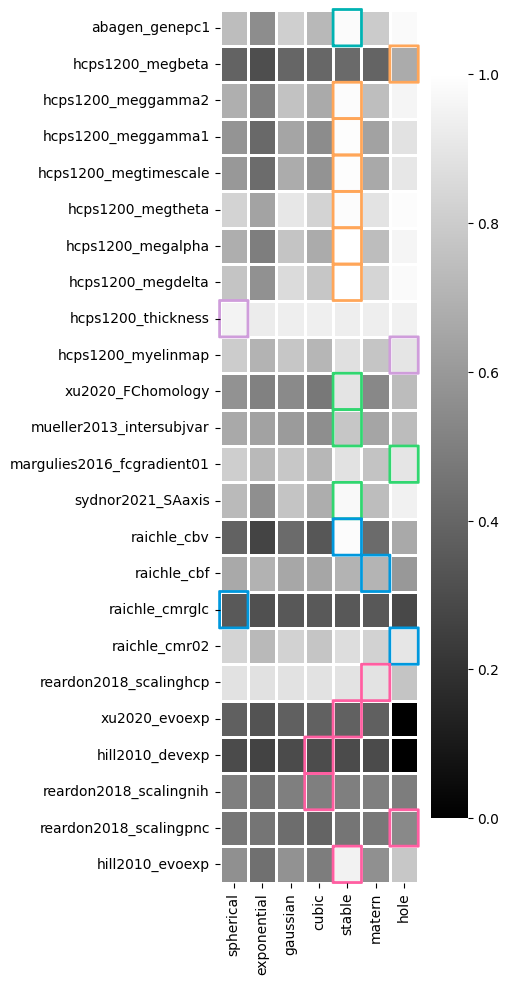

In [71]:
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
data = pd.DataFrame(matrix)
data.columns = maptags
fig, ax = plt.subplots(figsize = (5,10))
data = data[mapnames]
sns.heatmap(data.T, yticklabels = mapnames, \
            linewidth = 2, linecolor = 'w', xticklabels = skgstat_mdls.keys(), vmin =0, vmax = 1, cmap = 'gist_yarg_r', ax=ax)

row_labels = []

for maptag in mapnames:
    col_label = maptag
    row_label = data[maptag].sort_values(ascending = False).index[0]
    row_labels.append(row_label)


    j = data.index.get_loc(row_label)
    i = data.columns.get_loc(col_label)
    
    #ax.add_patch(
    #    plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="dimgray", linewidth=2)
    #)
    
    ax.add_patch(
        FancyBboxPatch(
            (j, i), 1, 1,
            boxstyle="round,pad=0.0001",
            linewidth=2,
            edgecolor=extended_cpal[maptag],
            facecolor="none", clip_on=False
        ))
    

plt.tight_layout()
plt.savefig(projdir + "/figs/rev_figs4_neuromaps_fit_vario.svg")

In [72]:
mdlnames = ['spherical', 'exponential', 'gaussian', 'cubic', 'stable', 'matern', 'hole']
show_models = [ mdlnames[ row_label ] for row_label in row_labels ]

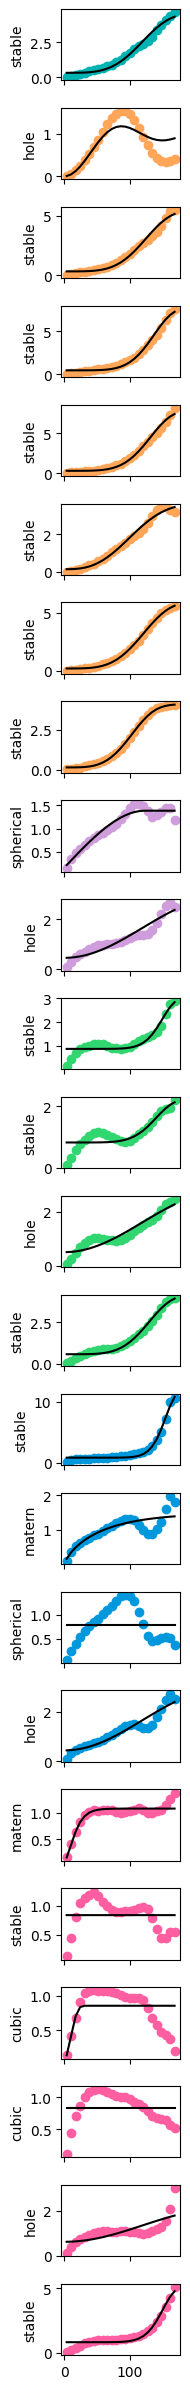

In [75]:
import matplotlib.pyplot as plt
import skgstat as skg
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics

fig, axs = plt.subplots(24, 1, figsize = (2,24), sharex=True)

for mi, mapname in enumerate(mapnames):
    ev = all_ev[:,mi]
    nh = 25
    
    p0 = {3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
              4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
             }

    mapvals = zscore(src_pvdata[mapname])
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}
    
    cof = None; cov = None
    
    gof = {}
        
    axs[mi].scatter(h, ev, color = extended_cpal[mapname])

    model = show_models[mi]
    if model in ['stable', 'matern']:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = bounds[4][1], bounds = bounds[4], maxfev=1000)
    
    else:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = bounds[3][1], bounds = bounds[3], maxfev=1000)

    v_pred = skgstat_mdls[model](h, *cof)
    x_s = np.linspace(h.min(), h.max())
    axs[mi].plot(h, v_pred, color = 'k')
    mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
    gof[model] = mae
    axs[mi].set_ylabel(model)
plt.tight_layout()
plt.savefig(projdir + "/figs/rev_figs4_neuromaps_little_variograms.svg")

* R1C5 \
Analysis design. There are concerns about i) generation of simulated data: Simulated data are generated based on variogram models, which may provide advantage to methods that involve variogram fitting (both using Gaussian variogram models). This is also a reviewer's comment that we received for our recent work, and to be honest I am not sure about the best way to address it. Simulation always relies on certain assumptions learned from empirical data, which are also used in methods to evaluate these data. Therefore, I am happy if the authors can implement kriging based on a different variogram model, or simply discuss this as a limitation.

In [2]:
from interpmodules import helpers

In [3]:
import joblib
sphere_mesh = joblib.load(projdir + '/data/fsLR-4k_sphere_grf.pkl')
instances = [ helpers.make_random_maps(ran=25, mesh=sphere_mesh, seed=i) for i in range(100) ]

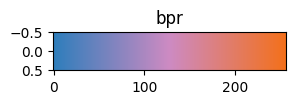

In [4]:
bpr,_ = three_colours_gradient(lo=plt.cm.Blues(0.7), mid=plt.cm.PuRd(0.4), hi=plt.cm.Oranges(0.6), plot=False)
show_colour_scheme(bpr, "bpr")

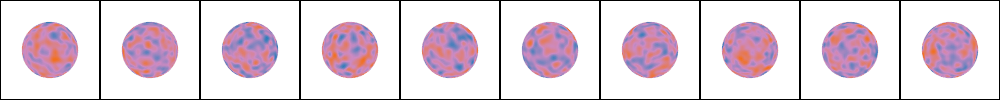

In [5]:
import pyvista as pv

pl = pv.Plotter(shape = (1,10), window_size = (1000, 100))

for i in range(10):
    pl.subplot(0,i)
    pl.add_mesh(sphere_mesh.rotate_z(180), scalars = instances[i], cmap = bpr, **mesh_aes)
    pl.camera_position = 'yz'
pl.show(jupyter_backend = 'static')

In [6]:
Dist = helpers.internal_distance_matrix(sphere_mesh.points, "euclidean")

In [8]:
nh=25
max_lag = Dist.max()
bin_edges = np.linspace(0.000001, max_lag, nh + 1)
bin_centers = [ ( bin_edges[i] + bin_edges[i + 1] ) / 2 for i in range(nh) ]

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

nreps = 100
ranges = [25, 50, 75, 100]

expv = {25: np.zeros((nreps, nh)), 50: np.zeros((nreps, nh)), 75: np.zeros((nreps, nh)), 100: np.zeros((nreps, nh))}
        
for ri, r in enumerate([25, 50, 75, 100]):
    instances = [ helpers.make_random_maps(ran=r, mesh=sphere_mesh, seed=i) for i in range(100) ]
    for i in range(100):
        h, ev, N = helpers.get_empirical_variogram_fast(x=instances[i],X=sphere_mesh.points,D=Dist,nh=25,h_bounds='auto', method='euclidean')
        expv[r][i,:] = ev


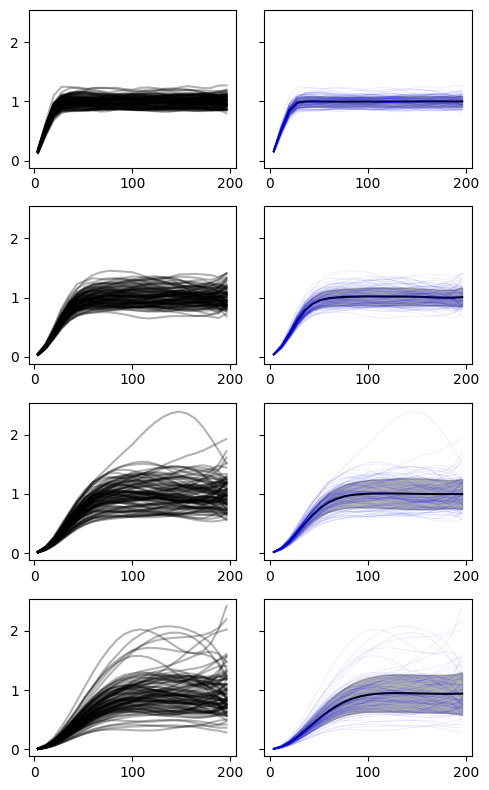

In [12]:
fig, axs = plt.subplots(4,2, figsize = (5, 8), sharey=True)

Dist = helpers.internal_distance_matrix(sphere_mesh.points, 'euclidean')
max_lag = Dist.max()
bin_edges = np.linspace(0.000001, max_lag, nh + 1)
bin_centers = [ ( bin_edges[i] + bin_edges[i + 1] ) / 2 for i in range(nh) ]

for ri, r in enumerate([25, 50, 75, 100]):
    expv_mu = expv[r].mean(axis=0)
    expv_sd = expv[r].std(axis = 0)

    axs[ri, 1].plot(h, expv_mu, c='k')

    axs[ri, 1].fill_between(x=h, y1=expv_mu - expv_sd, y2=expv_mu + expv_sd, edgecolor = 'none', color='dimgray', alpha = 0.5)
    
    for i in range(100):

        h = bin_centers
        ev = expv[r][i,:]

        axs[ri, 0].plot(h, ev, c='k', alpha = 0.3, rasterized=True)

        axs[ri, 1].plot(h, ev, c='b', alpha = 0.1, linewidth = .5, rasterized=True)

plt.tight_layout()
plt.show()

In [ ]:
# load even sampling



* R1C1: \
It makes sense to use Euclidean distance in simulations as they are generated in this space. For empirical surfaces, it remains unclear whether autocorrelation is best described in geodesic or Euclidean distances. Maybe worth reporting both if computationally feasible, I suspect the results would be very similar though.

In [4]:
import neuromaps.datasets
import nibabel as nb

fs4k = neuromaps.datasets.fetch_atlas(atlas='fsLR', density='4k')

gimg = nb.load(fs4k['midthickness'].L)
v,f = gimg.darrays[0].data, gimg.darrays[1].data
GDist = helpers.internal_distance_matrix(v,f, "geodesic")

/home/yzhou/anaconda3/envs/py311/lib/python3.11/site-packages/neuromaps/datasets/utils.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [5]:
medialwall = joblib.load(projdir + '/data/fsLR-4k_midthickness_neuromaps_medial_wall_mask.pkl')

In [6]:
tmp = np.delete(GDist, medialwall, axis=0)
tmp1 = np.delete(tmp, medialwall, axis=1)

GDist = tmp1

In [7]:
from interpmodules import helpers

global_i_s = pd.DataFrame(index = maptags, columns = ['i'])

for maptag in maptags:
    global_i = helpers.morans_i(GDist, src_pvdata[maptag], normalize=True)
    global_i_s.loc[maptag] = global_i

In [8]:
from scipy.sparse import coo_matrix

dist = 1 / GDist
np.fill_diagonal(dist, 0)
dist /= dist.sum(axis=-1, keepdims=True)
spdist = coo_matrix(dist)

/tmp/ipykernel_20831/2060558244.py:3: RuntimeWarning: divide by zero encountered in divide
  dist = 1 / GDist


In [9]:
def moran_permutation_test(x, W, n_perm, seed=0):
    rng = np.random.default_rng(seed)

    I_obs = helpers.morans_i(W, x, normalize=True, local=False, invert_dist=True)
    z = x - np.mean(x)

    # precompute denom for speed; permuting z doesn't change denom
    denom = np.dot(z, z)
    if denom == 0:
        return I_obs, np.nan, None

    Iz = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        zp = rng.permutation(z)
        Iz[b] = np.dot(zp, W @ zp) / denom

    # two sided
    p = (np.sum(np.abs(Iz) >= abs(I_obs)) + 1) / (n_perm + 1)

    return I_obs, p, Iz

In [10]:
pperm = np.zeros(len(maptags))
for mi, maptag in enumerate(maptags):
    pperm[mi] = moran_permutation_test(src_pvdata[maptag], dist, n_perm=1000)[1]

In [11]:
pperm

array([0.000999, 0.000999, 0.000999, 0.000999, 0.000999, 0.000999,
       0.000999, 0.000999, 0.000999, 0.000999, 0.000999, 0.000999,
       0.000999, 0.000999, 0.000999, 0.000999, 0.000999, 0.000999,
       0.000999, 0.000999, 0.000999, 0.000999, 0.000999, 0.000999])

In [12]:
maptocat = {'gene expression': ['abagen_genepc1'], \
            'MEG': ['hcps1200_meg' + fband for fband in fbands ] + ['hcps1200_megtimescale'], \
            'structural': ['hcps1200_thickness', 'hcps1200_myelinmap'], \
            'functional': ['margulies2016_fcgradient01', 'mueller2013_intersubjvar', 'xu2020_FChomology', 'sydnor2021_SAaxis'], \
            'metabolism': ['raichle_cbf', 'raichle_cbv', 'raichle_cmr02', 'raichle_cmrglc'], \
            'expansion': ['hill2010_devexp', 'hill2010_evoexp', 'xu2020_evoexp', 'reardon2018_scalinghcp', 'reardon2018_scalingnih', 'reardon2018_scalingpnc']}

In [13]:
cat = []
for row in range(len(global_i_s)):
    for category in maptocat:
        if global_i_s.index[row] in maptocat[category]:
            cat.append( category )
        else: continue

global_i_s['category'] = cat

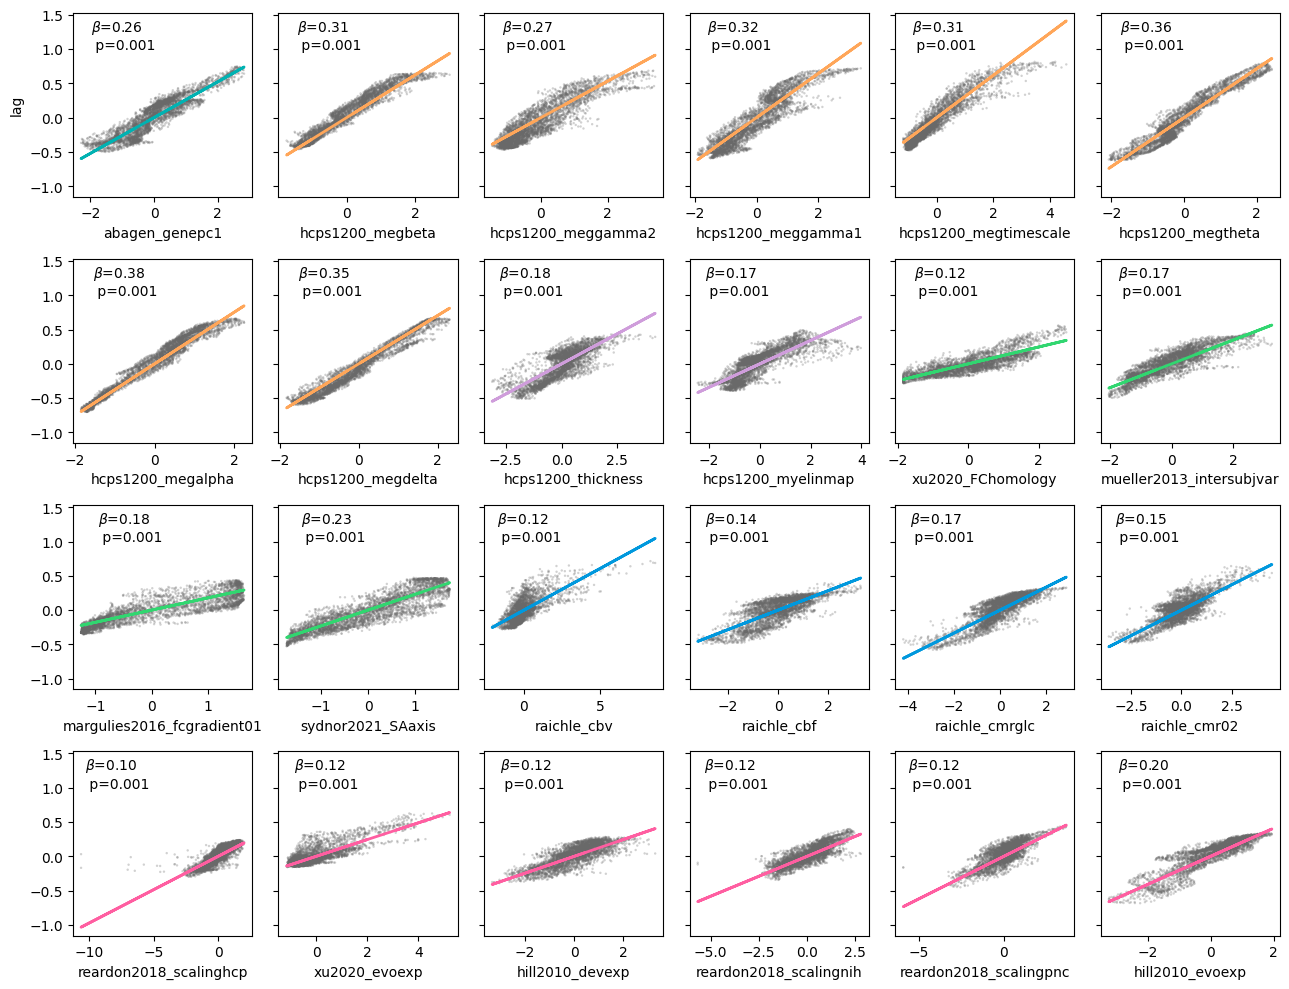

In [18]:
from scipy.stats import zscore

fig, axs = plt.subplots(4, 6, figsize = (13, 10), sharey=True)

moran_scatter = pd.DataFrame()

for mi, mapname in enumerate(mapnames):


    row, col = mi // 6, mi % 6
    
    zX = zscore(src_pvdata[mapname])
    #splag = np.average(np.repeat(zX[np.newaxis], src_pvdata.n_points, axis=0), weights=spdist, axis=1)
    splag = spdist @ zX
    normalized_og = zscore(src_pvdata[mapname])
    axs[row, col].scatter(x = zX, y =splag, s=3, c='dimgray', edgecolor = 'none', alpha = .3, rasterized = True)
    axs[row, col].set_xlabel(mapname)
    axs[0,0].set_ylabel("lag")

    #axs[mi].axhline(0, color="k", lw=1)
    #axs[mi].axvline(0, color="k", lw=1)
    
    # regression line
    m = (zX @ splag) / (zX @ zX)   # Moran's I
    moran_scatter.at[mi,0] = m
    axs[row,col].plot(zX, m * zX, linewidth = 2, color=cpal[global_i_s.at[mapname, 'category']])
    axs[row,col].text(x=zX.min() + 0.3, y=1, s=r"$\beta$=" + "%.2f" % m + "\n p=0.001")
plt.tight_layout()
plt.savefig(projdir + "/figs/rev_figs4_geodesic_ms.png", dpi=300)